# 회귀 실습

현대 중공업과 계약을 맺어 일부 선박에 대한 예측 모델을 구축하게됐습니다. 현대 중공업은 세계 최대의 선박 제조업체 중 하나로 유람선을 제작하고 있습니다.
당신은 선박에 필요한 선원 수를 정확하게 예측할 수 있도록 울산에있는 본사에 도착했습니다.
그들은 현재 새로운 선박을 건조하고 있으며 예측 모델을 만들고, 이를 사용하여 선박에 필요한 승무원 수를 예측하기를 원합니다.
    
데이터는 "cruise_ship_info.csv"라는 csv 파일에 저장됩니다. 귀하의 임무는 향후 선박에 필요한 선원 수를 예측하는 데 도움이되는 회귀 모델을 만드는 것입니다. 고객은 또한 특정 크루즈 라인이 허용되는 승무원 수에 차이가 있음을 발견 했으므로 분석에 포함하는 것이 가장 중요한 기능이라고 언급했습니다!

In [781]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from scipy import stats

In [908]:
df = pd.read_csv("./과제/회귀/cruise_ship_info.csv")
df.head()

,Ship_name,Cruise_line,Age,Tonnage,passengers,length,cabins,passenger_density,crew
0,Journey,Azamara,6,30.277,6.94,5.94,3.55,42.64,3.55
1,Quest,Azamara,6,30.277,6.94,5.94,3.55,42.64,3.55
2,Celebration,Carnival,26,47.262,14.86,7.22,7.43,31.80,6.70
3,Conquest,Carnival,11,110.000,29.74,9.53,14.88,36.99,19.10
4,Destiny,Carnival,17,101.353,26.42,8.92,13.21,38.36,10.00


In [910]:
df.shape

(158, 9)

In [912]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Ship_name          158 non-null    object 
 1   Cruise_line        158 non-null    object 
 2   Age                158 non-null    int64  
 3   Tonnage            158 non-null    float64
 4   passengers         158 non-null    float64
 5   length             158 non-null    float64
 6   cabins             158 non-null    float64
 7   passenger_density  158 non-null    float64
 8   crew               158 non-null    float64
dtypes: float64(6), int64(1), object(2)
memory usage: 11.2+ KB


In [914]:
df.describe()

,Age,Tonnage,passengers,length,cabins,passenger_density,crew
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000
mean,15.689873,71.284671,18.457405,8.130633,8.830000,39.900949,7.794177
std,7.615691,37.229540,9.677095,1.793474,4.471417,8.639217,3.503487
min,4.000000,2.329000,0.660000,2.790000,0.330000,17.700000,0.590000
25%,10.000000,46.013000,12.535000,7.100000,6.132500,34.570000,5.480000
50%,14.000000,71.899000,19.500000,8.555000,9.570000,39.085000,8.150000
75%,20.000000,90.772500,24.845000,9.510000,10.885000,44.185000,9.990000
max,48.000000,220.000000,54.000000,11.820000,27.000000,71.430000,21.000000


In [916]:
ndf = df[["Age","Tonnage","passengers", "length","cabins", "passenger_density","crew"]]
ndf.head()

,Age,Tonnage,passengers,length,cabins,passenger_density,crew
0,6,30.277,6.94,5.94,3.55,42.64,3.55
1,6,30.277,6.94,5.94,3.55,42.64,3.55
2,26,47.262,14.86,7.22,7.43,31.80,6.70
3,11,110.000,29.74,9.53,14.88,36.99,19.10
4,17,101.353,26.42,8.92,13.21,38.36,10.00


In [918]:
x = df.drop(["Ship_name", "Cruise_line", "crew"], axis = 1)
y = df["crew"]

In [920]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, random_state = 25)

In [922]:
print(x_train.shape, x_test.shape)

(118, 6) (40, 6)


# 선형 회귀 모델

In [925]:
lr = LinearRegression()

In [927]:
lr.fit(x_train, y_train)

LinearRegression()

In [929]:
# 결정계수
r_square = lr.score(x_test, y_test)

In [931]:
r_square

0.9396228022174195

In [933]:
x_train.head()

,Age,Tonnage,passengers,length,cabins,passenger_density
69,31,35.143,12.50,6.69,5.32,28.11
140,15,78.491,24.35,9.15,10.00,32.23
119,12,138.000,31.14,10.20,15.57,44.32
4,17,101.353,26.42,8.92,13.21,38.36
94,10,77.000,20.16,8.56,9.75,38.19


In [935]:
lr.coef_, lr.intercept_

(array([-0.00997809,  0.0087778 , -0.14992904,  0.43476877,  0.83119682,
         0.00806239]),
 -1.1114213693753792)

In [937]:
y_pred = lr.predict(x_test)

In [939]:
mse = mean_squared_error(y_test, y_pred)

In [941]:
mse

0.40565837684944717

In [943]:
pd.DataFrame({"ans": y_test, "pred": y_pred})

,ans,pred
21,10.00,10.664240
99,12.00,12.567236
96,12.20,11.395973
77,11.09,10.513912
79,4.38,4.573287
105,9.00,9.402821
26,9.09,8.435755
31,9.99,9.181784
101,12.38,11.370034
40,3.85,3.887530


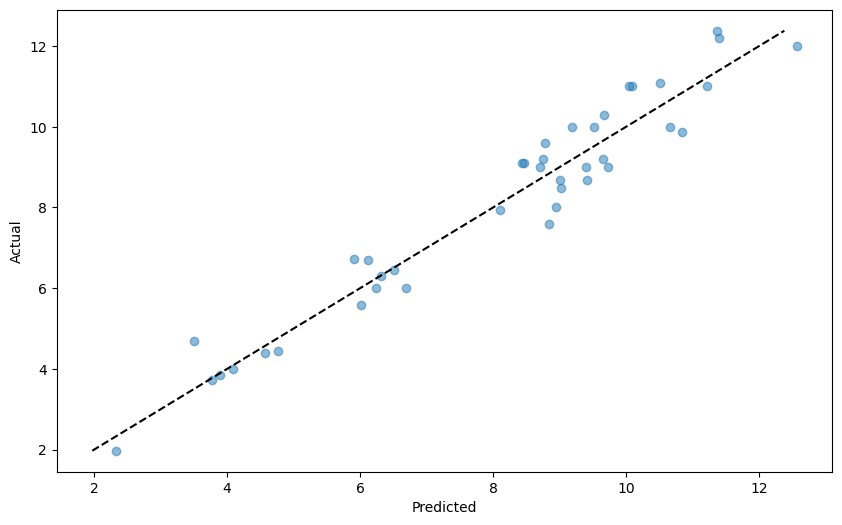

In [945]:
plt.figure(figsize = (10, 6))

plt.scatter(y_pred, y_test, alpha = 0.5)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], "k--")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [947]:
residuals = y_test - y_pred

In [949]:
residuals

21    -0.664240
99    -0.567236
96     0.804027
77     0.576088
79    -0.193287
105   -0.402821
26     0.654245
31     0.808216
101    1.009966
40    -0.037530
127   -0.716018
82    -0.006807
110    0.288403
115   -0.309072
65    -0.940023
120   -0.540336
52    -0.691476
97    -0.218799
113   -0.045461
41    -0.453385
135   -0.330358
78     0.908397
81     0.485454
125   -1.239277
54    -0.443500
121    0.801214
75     0.960719
30     0.583198
6      0.448029
85     0.806594
150    1.200854
34    -0.086963
148   -0.355176
49    -0.727125
20     0.628595
70    -0.971232
28     0.630902
95    -0.156248
42    -0.232391
58    -0.061871
Name: crew, dtype: float64

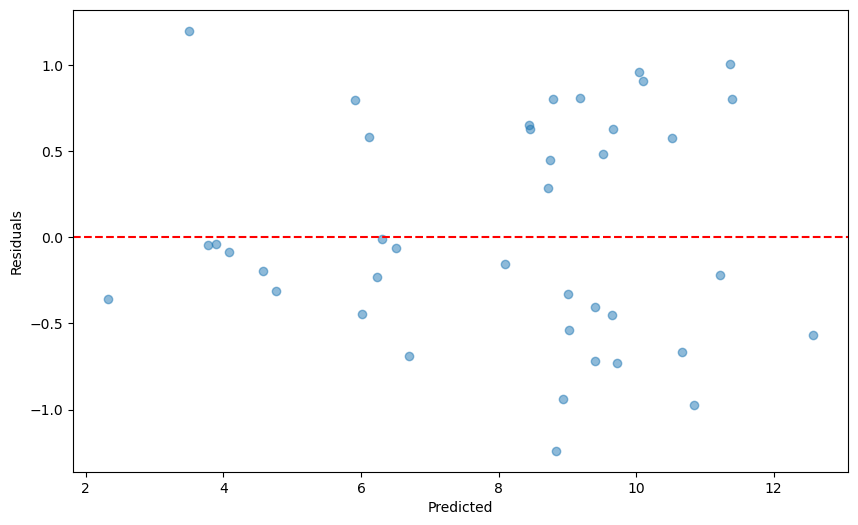

In [951]:
plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, alpha = 0.5)
plt.axhline(y = 0, color = "r", linestyle = "--")

plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.show()

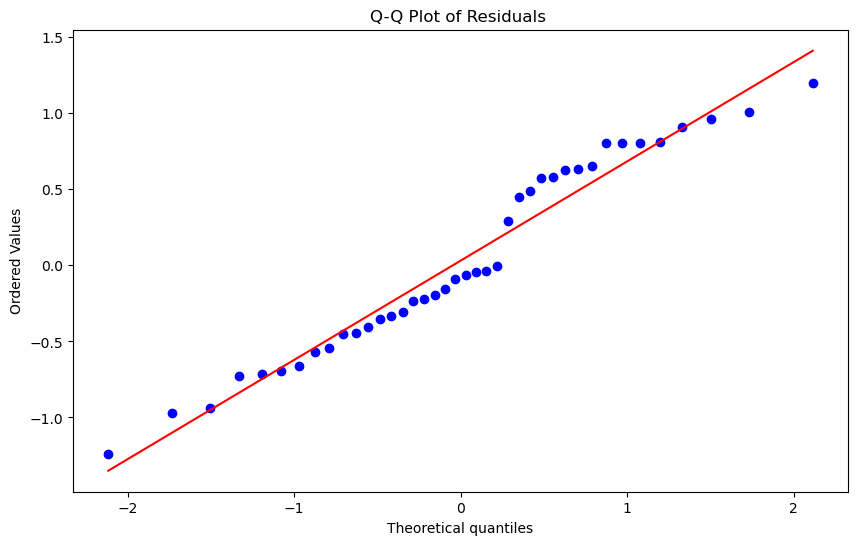

In [953]:
plt.figure(figsize=(10, 6))

stats.probplot(residuals.values.flatten(), dist = "norm", plot = plt)

plt.title("Q-Q Plot of Residuals ")
plt.show()

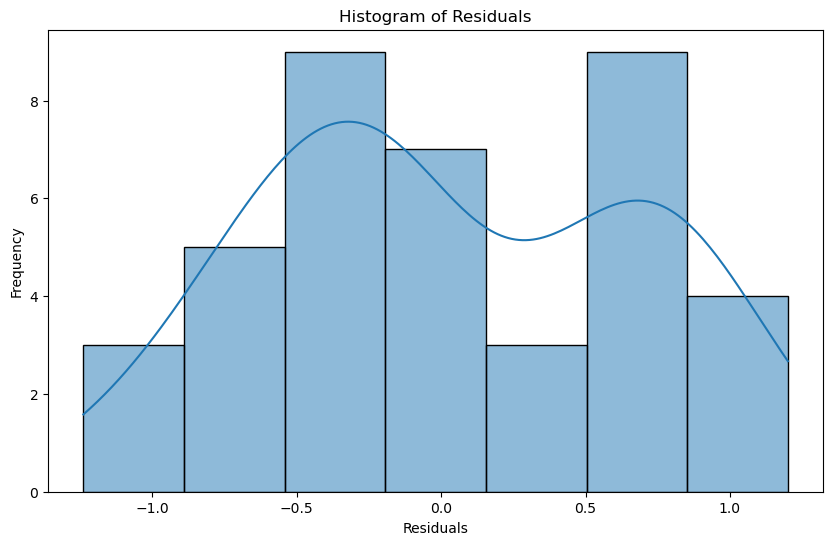

In [955]:
plt.figure(figsize=(10,6))

sns.histplot(residuals, kde = True)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")
plt.show()